# PHP_pre: raw vs. 60 Hz notch-filtered PSDs (halfwidth sweep: 2, 3, 4 Hz)

Runs the PHP.eB `PHP_pre` EDFs (`standard/`) through:

- `ebb.process.psd_compute.batch_estimate` — the shipped pipeline, no notch filter.
- `psd_compute_notch.batch_estimate` (this folder), once per notch halfwidth in
  `NOTCH_HALFWIDTHS` — identical pipeline, but the raw signal is bidirectionally
  notch-filtered (8th-order Butterworth, 60 Hz +/- halfwidth) before any masks
  or PSDs are computed.

All runs use the same `spindle_outputs/LFC_RSC` sleep-state CSVs, so results
line up animal-for-animal, behavior-for-behavior, with an identical frequency
axis (same `fs` and `resolution`). Later cells build a frequency-by-frequency
comparison across halfwidths, plus band-power and per-animal breakdowns.

Run in the `ebb-dev` environment.

In [289]:
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path("/Users/leahmcintyre/Developer/nri/ebb")
sys.path.insert(0, str(REPO_ROOT / "research" / "line_noise"))

from ebb.core.naming import parse_animal_id
from ebb.process.psd_compute import batch_estimate as batch_estimate_raw
import psd_compute_notch  # research-only module, not installed as a package

## Paths

In [290]:
EEG_DIR = Path("/Users/leahmcintyre/Data/nri/PHP.eB/PHP_pre/standard")
STATE_DIR = Path("/Users/leahmcintyre/Data/nri/PHP.eB/PHP_pre/spindle_outputs/LFC_RSC")

# Pickled results live outside the repo so they aren't at risk of being lost
# to branch switches/stashes (they aren't git-tracked either way).
OUT_DIR = Path("/Users/leahmcintyre/Data/nri/PHP.eB/PHP_pre/notch_trials")
RAW_PKL = OUT_DIR / "psds_php_pre_raw.pkl"

NOTCH_HALFWIDTHS = [2, 3, 4]  # Hz; stopband is 60 +/- halfwidth
NOTCH_PKLS = {hw: OUT_DIR / f"psds_php_pre_notch_h{hw}.pkl" for hw in NOTCH_HALFWIDTHS}

n_edfs = len(sorted(EEG_DIR.glob("*PROCESSED.edf")))
n_state = len(sorted(STATE_DIR.glob("*.csv")))
print(f"EDFs: {n_edfs}")
print(f"State CSVs: {n_state}")
print(f"Notch halfwidths to run: {NOTCH_HALFWIDTHS}")

EDFs: 38
State CSVs: 38
Notch halfwidths to run: [2, 3, 4]


## Run 1: original (unfiltered) pipeline

38 3-day EDFs at 250 Hz — this streams each file (commutator/SD/SPINDLE masks +
PSD) so it will take a while. Adjust `ncores` to taste; `None` auto-picks based
on core count and file count.

In [291]:
"""raw_results = batch_estimate_raw(
    eeg_dir=EEG_DIR,
    state_dir=STATE_DIR,
    ncores=6,
    fs=250,
    nstd=5,
    verbose=True,
    savepath=RAW_PKL,
)
print(f"Computed {len(raw_results)} PSD results (raw)")"""

'raw_results = batch_estimate_raw(\n    eeg_dir=EEG_DIR,\n    state_dir=STATE_DIR,\n    ncores=6,\n    fs=250,\n    nstd=5,\n    verbose=True,\n    savepath=RAW_PKL,\n)\nprint(f"Computed {len(raw_results)} PSD results (raw)")'

## Run 2: notch-filtered pipeline, once per halfwidth

Same kwargs, same state CSVs, one batch per entry in `NOTCH_HALFWIDTHS` — only
difference between runs is `notch_halfwidth_hz` passed to `estimate_psd`.

In [292]:
"""notch_results_by_hw = {}
for hw in NOTCH_HALFWIDTHS:
    print(f"--- notch halfwidth = {hw} Hz ---")
    notch_results_by_hw[hw] = psd_compute_notch.batch_estimate(
        eeg_dir=EEG_DIR,
        state_dir=STATE_DIR,
        ncores=6,
        fs=250,
        nstd=5,
        verbose=True,
        savepath=NOTCH_PKLS[hw],
        notch_halfwidth_hz=hw,
    )
    print(f"Computed {len(notch_results_by_hw[hw])} PSD results (notch, halfwidth={hw})")"""

'notch_results_by_hw = {}\nfor hw in NOTCH_HALFWIDTHS:\n    print(f"--- notch halfwidth = {hw} Hz ---")\n    notch_results_by_hw[hw] = psd_compute_notch.batch_estimate(\n        eeg_dir=EEG_DIR,\n        state_dir=STATE_DIR,\n        ncores=6,\n        fs=250,\n        nstd=5,\n        verbose=True,\n        savepath=NOTCH_PKLS[hw],\n        notch_halfwidth_hz=hw,\n    )\n    print(f"Computed {len(notch_results_by_hw[hw])} PSD results (notch, halfwidth={hw})")'

## Reload from disk

So the comparison cells below can be re-run without recomputing either batch.

In [293]:
def _simplify_behavior(records):
    """Collapse each record's ('threshold', state) behavior tuple down to just state."""
    for rec in records:
        rec["behavior"] = rec["behavior"][1]
    return records


with open(RAW_PKL, "rb") as f:
    raw_records = _simplify_behavior(pickle.load(f))

notch_records_by_hw = {}
for hw, pkl_path in NOTCH_PKLS.items():
    with open(pkl_path, "rb") as f:
        notch_records_by_hw[hw] = _simplify_behavior(pickle.load(f))

print(f"raw: {len(raw_records)} records")
for hw, recs in notch_records_by_hw.items():
    print(f"notch h={hw}: {len(recs)} records")

raw: 114 records
notch h=2: 114 records
notch h=3: 114 records
notch h=4: 114 records


## Sanity checks: matched animals/behaviors, identical frequency axis

In [294]:
def record_key(rec):
    return (parse_animal_id(Path(rec["path"])), rec["behavior"])

raw_by_key = {record_key(r): r for r in raw_records}
notch_by_key_by_hw = {
    hw: {record_key(r): r for r in recs} for hw, recs in notch_records_by_hw.items()
}

common_keys = sorted(
    set(raw_by_key).intersection(*(set(d) for d in notch_by_key_by_hw.values()))
)
print(f"{len(common_keys)} (animal, behavior) pairs common to raw + all halfwidths")

for hw, notch_by_key in notch_by_key_by_hw.items():
    missing_in_notch = set(raw_by_key) - set(notch_by_key)
    missing_in_raw = set(notch_by_key) - set(raw_by_key)
    freqs_match = all(
        np.array_equal(raw_by_key[k]["freqs"], notch_by_key[k]["freqs"]) for k in common_keys
    )
    print(
        f"h={hw}: only in raw={len(missing_in_notch)}, only in notch={len(missing_in_raw)}, "
        f"freq axes identical={freqs_match}"
    )

114 (animal, behavior) pairs common to raw + all halfwidths
h=2: only in raw=0, only in notch=0, freq axes identical=True
h=3: only in raw=0, only in notch=0, freq axes identical=True
h=4: only in raw=0, only in notch=0, freq axes identical=True


## Tidy long-format comparison table

One row per (halfwidth, animal, behavior, channel, freq) with both PSD values
side by side in dB, so any frequency-by-frequency comparison downstream is a
groupby on `df`.

In [295]:
rows = []
for hw, notch_by_key in notch_by_key_by_hw.items():
    for _animal, _behavior in common_keys:
        _r_raw = raw_by_key[(_animal, _behavior)]
        _r_notch = notch_by_key[(_animal, _behavior)]
        _freqs = np.asarray(_r_raw["freqs"])
        psd_raw = np.asarray(_r_raw["psd"])      # (n_channels, n_freqs)
        psd_notch = np.asarray(_r_notch["psd"])
        for ci, ch in enumerate(_r_raw["channels"]):
            rows.append(
                pd.DataFrame(
                    {
                        "halfwidth": hw,
                        "animal": _animal,
                        "behavior": _behavior,
                        "channel": ch,
                        "freq": _freqs,
                        "psd_raw": psd_raw[ci],
                        "psd_notch": psd_notch[ci],
                    }
                )
            )

df = pd.concat(rows, ignore_index=True)
df["db_raw"] = 10 * np.log10(df["psd_raw"])
df["db_notch"] = 10 * np.log10(df["psd_notch"])
df["delta_db"] = df["db_notch"] - df["db_raw"]  # negative => notch removed power there
df.head()

,halfwidth,animal,behavior,channel,freq,psd_raw,psd_notch,db_raw,db_notch,delta_db
0,2,CW0DA1,nrem,0,0.0,8.730157,8.548415,9.410221,9.318856,-0.091365
1,2,CW0DA1,nrem,0,0.5,32.696114,32.683731,15.144961,15.143316,-0.001645
2,2,CW0DA1,nrem,0,1.0,81.456056,81.013395,19.109234,19.085568,-0.023665
3,2,CW0DA1,nrem,0,1.5,149.462854,149.142312,21.745333,21.736009,-0.009324
4,2,CW0DA1,nrem,0,2.0,221.127846,221.390342,23.446434,23.451587,0.005152


## Plot: mean effect of the notch filter vs. frequency, by halfwidth

Averaged across all animals/behaviors/channels — each curve should show a
dip in `delta_db` centered on 60 Hz, widening as `halfwidth` grows, and ~0
everywhere else.

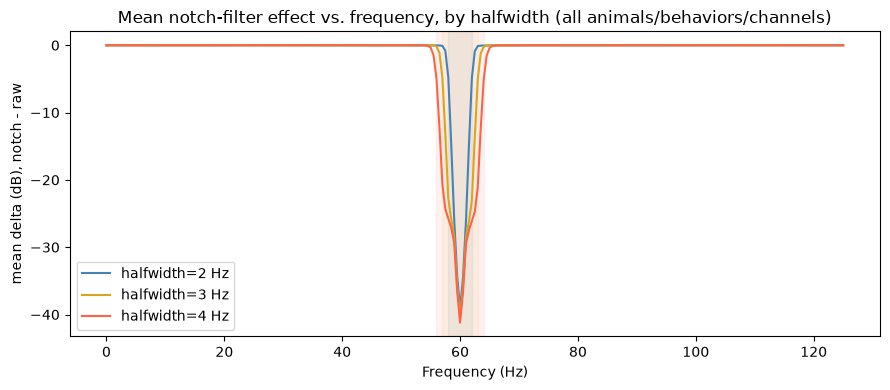

In [296]:
hw_colors = {2: "steelblue", 3: "goldenrod", 4: "tomato"}
mean_delta_by_hw = {
    hw: sub.groupby("freq")["delta_db"].mean() for hw, sub in df.groupby("halfwidth")
}

fig, ax = plt.subplots(figsize=(9, 4))
for hw, mean_delta in mean_delta_by_hw.items():
    color = hw_colors.get(hw, None)
    ax.plot(mean_delta.index, mean_delta.values, label=f"halfwidth={hw} Hz", color=color)
    ax.axvspan(60 - hw, 60 + hw, color=color, alpha=0.08)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean delta (dB), notch - raw")
ax.set_title("Mean notch-filter effect vs. frequency, by halfwidth (all animals/behaviors/channels)")
ax.legend()
fig.tight_layout()

## Plot: one animal/behavior, raw vs. all notch halfwidths

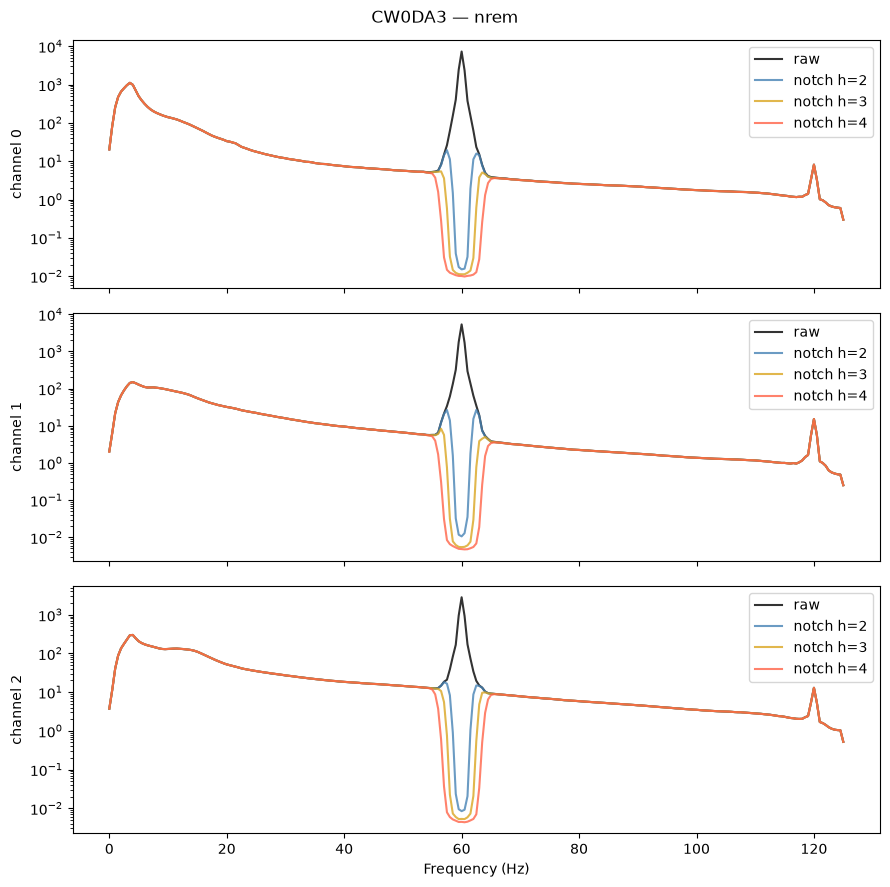

In [297]:
# Edit these to look at a different animal/behavior -- every cell below
# (this plot, the interpolated version, and the method-comparison plot)
# follows from animal/behavior/r_raw/freqs/channels set here.
ANIMAL = "CW0DA3"
BEHAVIOR = "nrem"  # "wake" / "nrem" / "rem"

available_animals = sorted({a for a, b in common_keys})
if (ANIMAL, BEHAVIOR) not in common_keys:
    raise ValueError(
        f"{(ANIMAL, BEHAVIOR)!r} not in common_keys.\n"
        f"Available animals: {available_animals}\n"
        f"Available behaviors: {sorted({b for a, b in common_keys})}"
    )
animal, behavior = ANIMAL, BEHAVIOR

r_raw = raw_by_key[(animal, behavior)]
freqs = np.asarray(r_raw["freqs"])
channels = r_raw["channels"]

fig, axes = plt.subplots(len(channels), 1, figsize=(9, 3 * len(channels)), sharex=True)
axes = np.atleast_1d(axes)
for ci, ch in enumerate(channels):
    axes[ci].semilogy(freqs, r_raw["psd"][ci], label="raw", color="black", alpha=0.8)
    for hw, notch_by_key in notch_by_key_by_hw.items():
        r_notch = notch_by_key[(animal, behavior)]
        axes[ci].semilogy(
            freqs, r_notch["psd"][ci], label=f"notch h={hw}", color=hw_colors.get(hw), alpha=0.8
        )
    axes[ci].set_ylabel(f"channel {ch}")
    axes[ci].legend()
axes[-1].set_xlabel("Frequency (Hz)")
fig.suptitle(f"{animal} — {behavior}")
fig.tight_layout()

### Same plot, interpolated over a specified range

Same animal/behavior/channels as above, but each curve (raw and every notch
halfwidth) is shown after `specparam`'s `interpolate_spectrum` fills in
`SINGLE_PLOT_INTERP_RANGE` — no uninterpolated curves this time. Edit that
range (and `SINGLE_PLOT_INTERP_BUFFER`) below to try others — it's
independent of `INTERP_RANGE` used in the full interpolated-comparison
section further down.

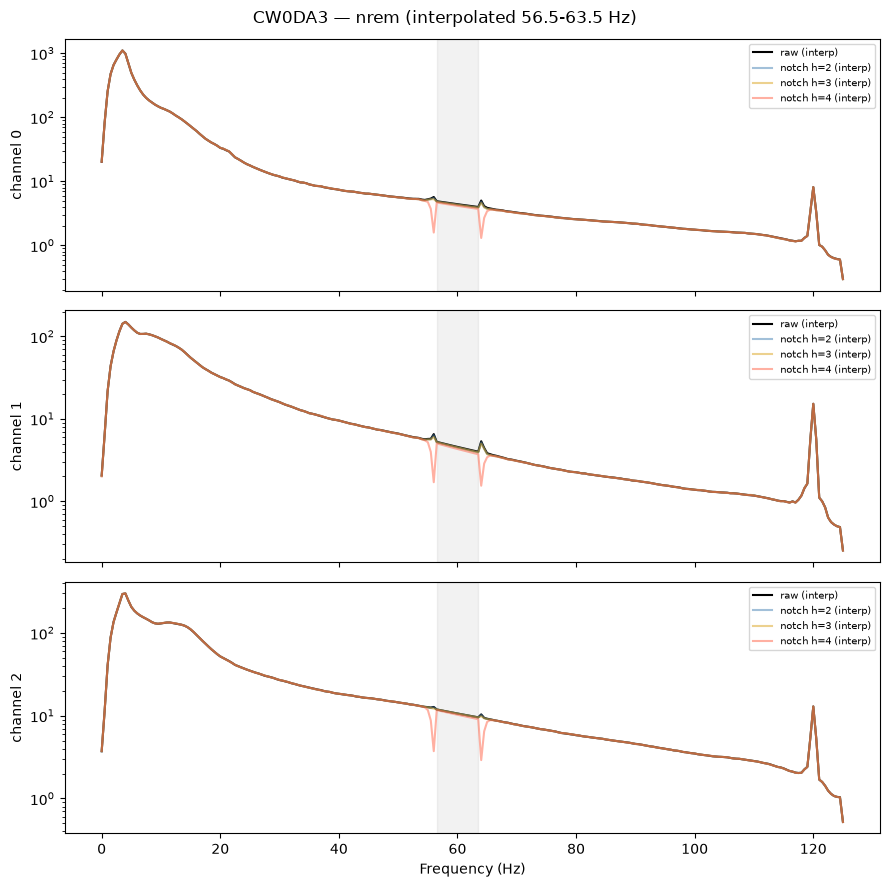

In [298]:
from specparam.utils.spectral import interpolate_spectrum

# Edit these to try a different interpolation window for this plot only.
SINGLE_PLOT_INTERP_RANGE = [56.5, 63.5]
SINGLE_PLOT_INTERP_BUFFER = 10


def _interp_curve(freqs, psd_1d, interp_range=SINGLE_PLOT_INTERP_RANGE, buffer=SINGLE_PLOT_INTERP_BUFFER):
    return interpolate_spectrum(freqs, psd_1d, interp_range, buffer=buffer)[1]


fig, axes = plt.subplots(len(channels), 1, figsize=(9, 3 * len(channels)), sharex=True)
axes = np.atleast_1d(axes)
for ci, ch in enumerate(channels):
    raw_curve = r_raw["psd"][ci]
    axes[ci].semilogy(freqs, _interp_curve(freqs, raw_curve), label="raw (interp)", color="black", alpha=1)
    for hw, notch_by_key in notch_by_key_by_hw.items():
        notch_curve = notch_by_key[(animal, behavior)]["psd"][ci]
        color = hw_colors.get(hw)
        axes[ci].semilogy(
            freqs, _interp_curve(freqs, notch_curve), label=f"notch h={hw} (interp)", color=color, alpha=0.5
        )
    axes[ci].axvspan(*SINGLE_PLOT_INTERP_RANGE, color="gray", alpha=0.1)
    axes[ci].set_ylabel(f"channel {ch}")
    axes[ci].legend(fontsize=7)
axes[-1].set_xlabel("Frequency (Hz)")
fig.suptitle(
    f"{animal} — {behavior} "
    f"(interpolated {SINGLE_PLOT_INTERP_RANGE[0]}-{SINGLE_PLOT_INTERP_RANGE[1]} Hz)"
)
fig.tight_layout()

## Band power comparison (raw vs. notch, by halfwidth)

The delta spectrum above answers "did the filter behave" (dip at 60 Hz, flat
elsewhere). This section answers the question that actually matters for
downstream analysis: does removing the 60 Hz line change the *band powers*
you'd report, and does that change grow with `halfwidth`? Bands follow the
convention used in `research/psd_from_edfs.ipynb` (trapezoidal integration of
the PSD), plus a `gamma` band below the notch and a `line` band (55-65 Hz,
wide enough to fully contain the widest halfwidth tested) so the line-noise
effect is visible directly instead of only by omission.

In [299]:
BANDS = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
    "gamma": (30, 55),
    "line": (55, 65),  # fixed, wide enough to contain every tested halfwidth
}


def band_power(freqs, psd_arr, lo, hi):
    """Integrate PSD between lo and hi Hz using the trapezoidal rule."""
    mask = (freqs >= lo) & (freqs <= hi)
    return np.trapezoid(psd_arr[mask], freqs[mask])


band_rows = []
for hw, notch_by_key in notch_by_key_by_hw.items():
    for _animal, _behavior in common_keys:
        _r_raw = raw_by_key[(_animal, _behavior)]
        _r_notch = notch_by_key[(_animal, _behavior)]
        _freqs = np.asarray(_r_raw["freqs"])
        psd_raw = np.asarray(_r_raw["psd"])
        psd_notch = np.asarray(_r_notch["psd"])
        for ci, ch in enumerate(_r_raw["channels"]):
            for band, (lo, hi) in BANDS.items():
                p_raw = band_power(_freqs, psd_raw[ci], lo, hi)
                p_notch = band_power(_freqs, psd_notch[ci], lo, hi)
                band_rows.append(
                    {
                        "halfwidth": hw,
                        "animal": _animal,
                        "behavior": _behavior,
                        "channel": ch,
                        "band": band,
                        "power_raw": p_raw,
                        "power_notch": p_notch,
                        "delta_db": 10 * np.log10(p_notch / p_raw),
                    }
                )

bands_df = pd.DataFrame(band_rows)
bands_df.head()

,halfwidth,animal,behavior,channel,band,power_raw,power_notch,delta_db
0,2,CW0DA1,nrem,0,delta,822.294062,821.847462,-0.002359
1,2,CW0DA1,nrem,0,theta,1116.054697,1115.058089,-0.003880
2,2,CW0DA1,nrem,0,alpha,911.785848,912.368604,0.002775
3,2,CW0DA1,nrem,0,beta,1129.168747,1129.579622,0.001580
4,2,CW0DA1,nrem,0,gamma,270.184353,270.615813,0.006930


In [300]:
band_order = list(BANDS.keys())
band_summary = (
    bands_df.groupby(["band", "halfwidth"])["delta_db"]
    .agg(["mean", "sem"])
    .reindex(band_order, level="band")
)
band_summary

mean       sem
band  halfwidth                     
delta 2          -0.007530  0.000859
      3          -0.007601  0.000859
      4          -0.007531  0.000899
theta 2          -0.008048  0.000923
      3          -0.007872  0.000935
      4          -0.007527  0.000954
alpha 2          -0.006225  0.000869
      3          -0.006348  0.000837
      4          -0.005715  0.000864
beta  2          -0.005925  0.000910
      3          -0.004910  0.000959
      4          -0.003864  0.000994
gamma 2          -0.001528  0.000768
      3           0.000242  0.000914
      4          -0.001633  0.001056
line  2          -8.737809  0.128440
      3         -10.952667  0.145104
      4         -14.594601  0.150397

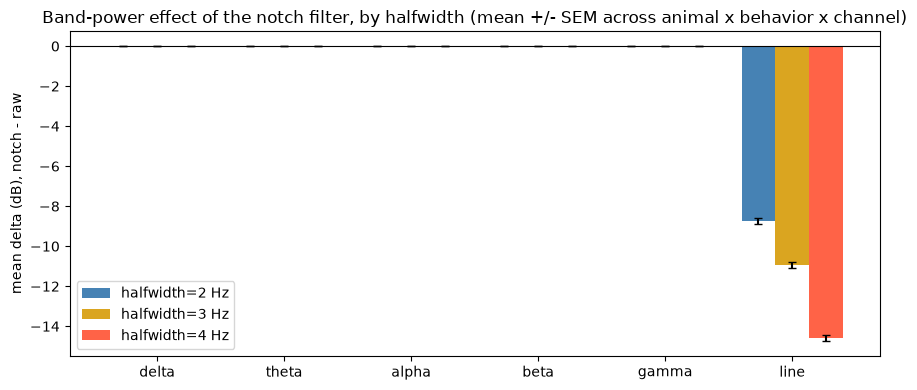

In [301]:
x = np.arange(len(band_order))
width = 0.8 / len(NOTCH_HALFWIDTHS)

fig, ax = plt.subplots(figsize=(9, 4))
for i, hw in enumerate(NOTCH_HALFWIDTHS):
    means = [band_summary.loc[(band, hw), "mean"] for band in band_order]
    sems = [band_summary.loc[(band, hw), "sem"] for band in band_order]
    ax.bar(
        x + (i - (len(NOTCH_HALFWIDTHS) - 1) / 2) * width,
        means,
        width=width,
        yerr=sems,
        capsize=3,
        label=f"halfwidth={hw} Hz",
        color=hw_colors.get(hw),
    )
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(band_order)
ax.set_ylabel("mean delta (dB), notch - raw")
ax.set_title("Band-power effect of the notch filter, by halfwidth (mean +/- SEM across animal x behavior x channel)")
ax.legend()
fig.tight_layout()

If the notch is well-behaved, `delta`/`theta`/`alpha`/`beta`/`gamma` bars
should sit at ~0 dB for every halfwidth (no collateral change to bands you'd
actually report), and only `line` should show a large negative bar that grows
(more negative) as `halfwidth` increases — that's more line noise being
removed, not a change in the underlying signal.

## Per-animal spectrum of the notch effect, by halfwidth (spaghetti plot)

The mean plot above can hide per-animal outliers (e.g. one animal with a
broader line-noise footprint, or harmonic leakage at 120 Hz). Plotting every
animal's delta spectrum as a thin line behind the group mean surfaces that,
faceted here by halfwidth so the widening stopband is easy to compare.

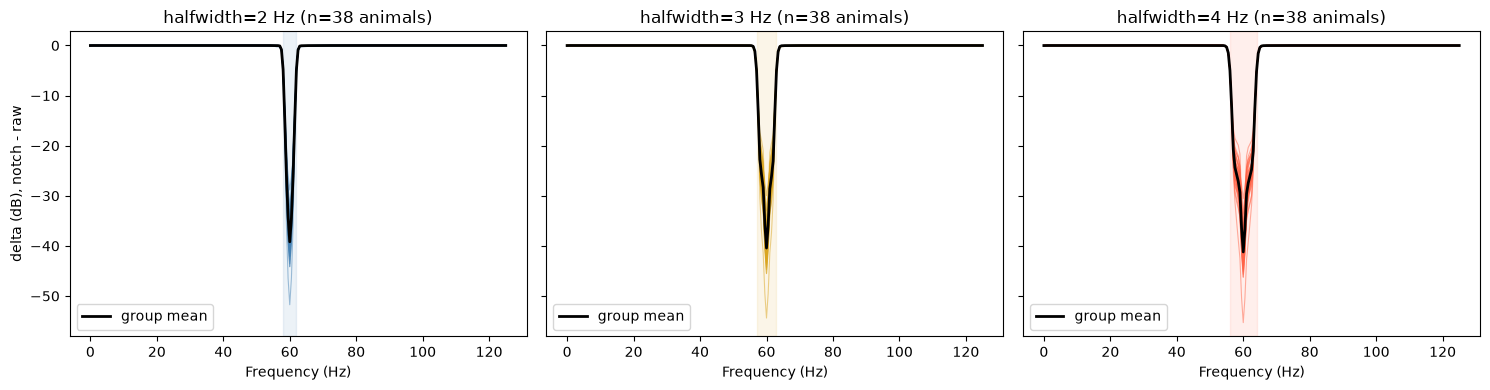

In [302]:
fig, axes = plt.subplots(1, len(NOTCH_HALFWIDTHS), figsize=(5 * len(NOTCH_HALFWIDTHS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, hw in zip(axes, NOTCH_HALFWIDTHS):
    sub = df[df["halfwidth"] == hw]
    per_animal_delta = sub.groupby(["animal", "freq"])["delta_db"].mean().unstack("freq")
    for _animal, row in per_animal_delta.iterrows():
        ax.plot(row.index, row.values, lw=0.8, alpha=0.5, color=hw_colors.get(hw))
    ax.plot(
        mean_delta_by_hw[hw].index, mean_delta_by_hw[hw].values, color="black", lw=2, label="group mean"
    )
    ax.axvspan(60 - hw, 60 + hw, color=hw_colors.get(hw), alpha=0.1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_title(f"halfwidth={hw} Hz (n={per_animal_delta.shape[0]} animals)")
    ax.legend()
axes[0].set_ylabel("delta (dB), notch - raw")
fig.tight_layout()

## Percent-difference comparison

Same frequency-by-frequency and band-power comparisons as above, but
expressed as percent difference (`(notch - raw) / raw * 100`) instead of dB.
dB compresses large ratios (useful for the deep notch itself) but percent
difference is often the more intuitive unit for "how much did this band's
power change" outside the notch.

In [303]:
df["pct_diff"] = (df["psd_notch"] / df["psd_raw"] - 1) * 100
bands_df["power_pct_diff"] = (bands_df["power_notch"] / bands_df["power_raw"] - 1) * 100
df[["halfwidth", "animal", "behavior", "channel", "freq", "delta_db", "pct_diff"]].head()

,halfwidth,animal,behavior,channel,freq,delta_db,pct_diff
0,2,CW0DA1,nrem,0,0.0,-0.091365,-2.081777
1,2,CW0DA1,nrem,0,0.5,-0.001645,-0.037874
2,2,CW0DA1,nrem,0,1.0,-0.023665,-0.543436
3,2,CW0DA1,nrem,0,1.5,-0.009324,-0.214463
4,2,CW0DA1,nrem,0,2.0,0.005152,0.118708


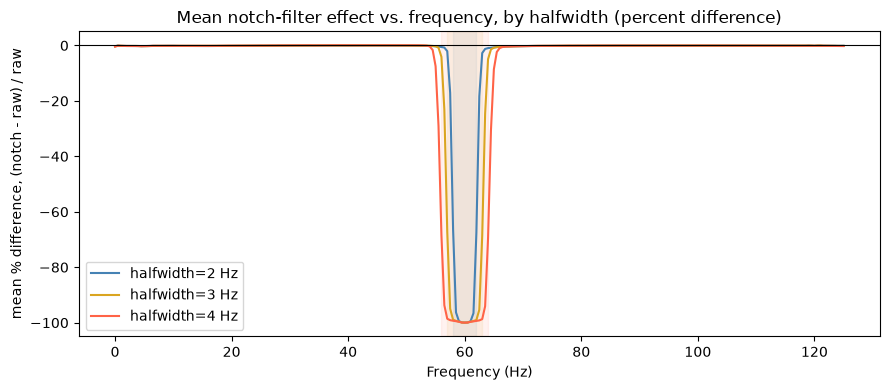

In [304]:
mean_pct_by_hw = {hw: sub.groupby("freq")["pct_diff"].mean() for hw, sub in df.groupby("halfwidth")}

fig, ax = plt.subplots(figsize=(9, 4))
for hw, mean_pct in mean_pct_by_hw.items():
    color = hw_colors.get(hw)
    ax.plot(mean_pct.index, mean_pct.values, label=f"halfwidth={hw} Hz", color=color)
    ax.axvspan(60 - hw, 60 + hw, color=color, alpha=0.08)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean % difference, (notch - raw) / raw")
ax.set_title("Mean notch-filter effect vs. frequency, by halfwidth (percent difference)")
ax.legend()
fig.tight_layout()

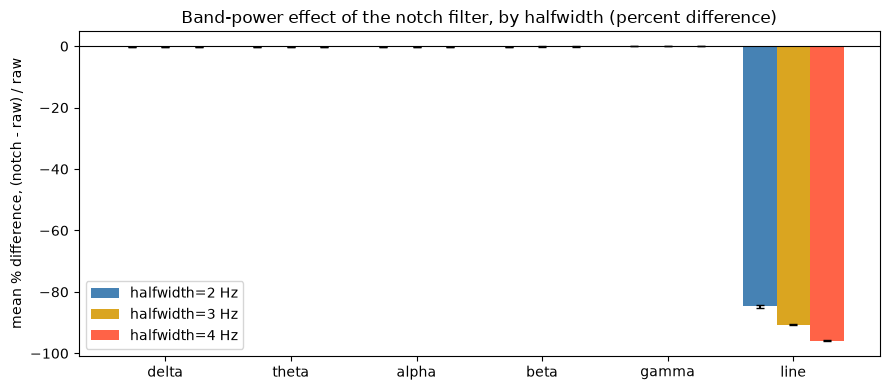

In [305]:
band_summary_pct = (
    bands_df.groupby(["band", "halfwidth"])["power_pct_diff"]
    .agg(["mean", "sem"])
    .reindex(band_order, level="band")
)

fig, ax = plt.subplots(figsize=(9, 4))
for i, hw in enumerate(NOTCH_HALFWIDTHS):
    means = [band_summary_pct.loc[(band, hw), "mean"] for band in band_order]
    sems = [band_summary_pct.loc[(band, hw), "sem"] for band in band_order]
    ax.bar(
        x + (i - (len(NOTCH_HALFWIDTHS) - 1) / 2) * width,
        means,
        width=width,
        yerr=sems,
        capsize=3,
        label=f"halfwidth={hw} Hz",
        color=hw_colors.get(hw),
    )
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(band_order)
ax.set_ylabel("mean % difference, (notch - raw) / raw")
ax.set_title("Band-power effect of the notch filter, by halfwidth (percent difference)")
ax.legend()
fig.tight_layout()

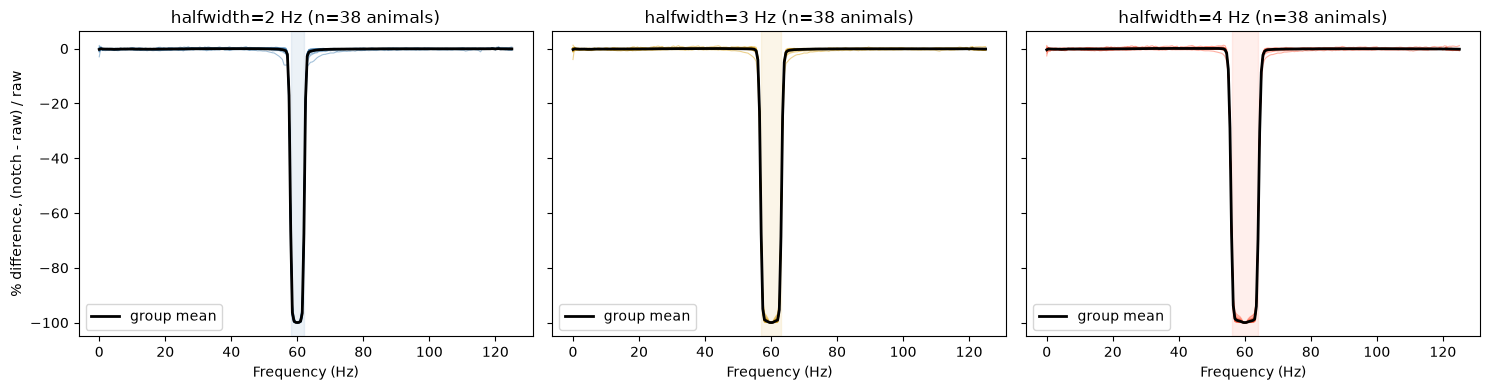

In [306]:
fig, axes = plt.subplots(1, len(NOTCH_HALFWIDTHS), figsize=(5 * len(NOTCH_HALFWIDTHS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, hw in zip(axes, NOTCH_HALFWIDTHS):
    sub = df[df["halfwidth"] == hw]
    per_animal_pct = sub.groupby(["animal", "freq"])["pct_diff"].mean().unstack("freq")
    for _animal, row in per_animal_pct.iterrows():
        ax.plot(row.index, row.values, lw=0.8, alpha=0.5, color=hw_colors.get(hw))
    ax.plot(mean_pct_by_hw[hw].index, mean_pct_by_hw[hw].values, color="black", lw=2, label="group mean")
    ax.axvspan(60 - hw, 60 + hw, color=hw_colors.get(hw), alpha=0.1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_title(f"halfwidth={hw} Hz (n={per_animal_pct.shape[0]} animals)")
    ax.legend()
axes[0].set_ylabel("% difference, (notch - raw) / raw")
fig.tight_layout()

## Interpolated comparison: fill 57-63 Hz before comparing

The notch is *designed* to remove power in its stopband, so comparing raw vs.
notch across 57-63 Hz trivially shows a large difference (that's the `line`
band above). This section asks a different question: if that region is
excised and reconstructed by interpolation instead, is there still a
difference anywhere?

Interpolation uses `interpolate_spectrum` from `specparam`
(the actively-maintained successor to `fooof`; `fooof.utils.data.interpolate_spectrum`
is the same implementation but deprecated). It differs from a naive linear fill in
two ways:
- it interpolates in **log-log space**, following the spectrum's 1/f-like shape
  instead of drawing a flat line across the gap;
- its two anchors are the **median** (not mean) of the `buffer` bins on each
  side of the window, which is more robust to any single noisy bin.

We use `interp_range=[57, 63]` and `buffer=10`, matching the window and
point count discussed earlier. The same recipe is applied to both raw and
notch curves, so this isn't "notch vs. untouched raw" — it's "notch vs. a raw
curve that's also had its 57-63 Hz region idealized away."

One wrinkle worth watching for: the interpolation window (57-63 Hz) doesn't
line up with every stopband tested. `halfwidth=2` (stopband 58-62 Hz) sits
comfortably inside the window, so its anchor points (well below 57, well
above 63) should be close to undisturbed and interpolation should nearly
erase the `line`-band difference. `halfwidth=3` (stopband 57-63 Hz) matches
the window almost exactly, so its anchors sit right at the edge of
attenuation. `halfwidth=4` (stopband 56-64 Hz) extends *past* the window on
both sides, so some of the 10 anchor bins on each side themselves fall inside
the attenuated region — interpolation can't fully undo that, and some
residual difference in `line` is expected to remain for that halfwidth
specifically.

# Change HERE

In [307]:
from specparam.utils.spectral import interpolate_spectrum

INTERP_RANGE = [56, 64]
INTERP_BUFFER = 3


def interpolate_record(rec, interp_range=INTERP_RANGE, buffer=INTERP_BUFFER):
    """Return a copy of a PSDResult dict with every channel's psd interpolated
    across interp_range Hz via specparam's log-log, median-anchored recipe."""
    freqs = np.asarray(rec["freqs"])
    psd = np.asarray(rec["psd"])
    interp_psd = np.stack(
        [interpolate_spectrum(freqs, psd[ci], interp_range, buffer=buffer)[1] for ci in range(psd.shape[0])]
    )
    out = dict(rec)
    out["psd"] = interp_psd
    return out


raw_by_key_interp = {k: interpolate_record(r) for k, r in raw_by_key.items()}
notch_by_key_by_hw_interp = {
    hw: {k: interpolate_record(r) for k, r in notch_by_key.items()}
    for hw, notch_by_key in notch_by_key_by_hw.items()
}
print(f"Interpolated raw + all halfwidths across {INTERP_RANGE} Hz (specparam, buffer={INTERP_BUFFER})")

Interpolated raw + all halfwidths across [56, 64] Hz (specparam, buffer=3)


## subsets

In [308]:
rows_interp = []
for hw, notch_by_key_interp in notch_by_key_by_hw_interp.items():
    for _animal, _behavior in common_keys:
        _r_raw = raw_by_key_interp[(_animal, _behavior)]
        _r_notch = notch_by_key_interp[(_animal, _behavior)]
        _freqs = np.asarray(_r_raw["freqs"])
        psd_raw = np.asarray(_r_raw["psd"])
        psd_notch = np.asarray(_r_notch["psd"])
        for ci, ch in enumerate(_r_raw["channels"]):
            rows_interp.append(
                pd.DataFrame(
                    {
                        "halfwidth": hw,
                        "animal": _animal,
                        "behavior": _behavior,
                        "channel": ch,
                        "freq": _freqs,
                        "psd_raw": psd_raw[ci],
                        "psd_notch": psd_notch[ci],
                    }
                )
            )

df_interp = pd.concat(rows_interp, ignore_index=True)
df_interp["delta_db"] = 10 * np.log10(df_interp["psd_notch"]) - 10 * np.log10(df_interp["psd_raw"])
df_interp["pct_diff"] = (df_interp["psd_notch"] / df_interp["psd_raw"] - 1) * 100
df_interp.head()

,halfwidth,animal,behavior,channel,freq,psd_raw,psd_notch,delta_db,pct_diff
0,2,CW0DA1,nrem,0,0.0,8.730157,8.548415,-0.091365,-2.081777
1,2,CW0DA1,nrem,0,0.5,32.696114,32.683731,-0.001645,-0.037874
2,2,CW0DA1,nrem,0,1.0,81.456056,81.013395,-0.023665,-0.543436
3,2,CW0DA1,nrem,0,1.5,149.462854,149.142312,-0.009324,-0.214463
4,2,CW0DA1,nrem,0,2.0,221.127846,221.390342,0.005152,0.118708


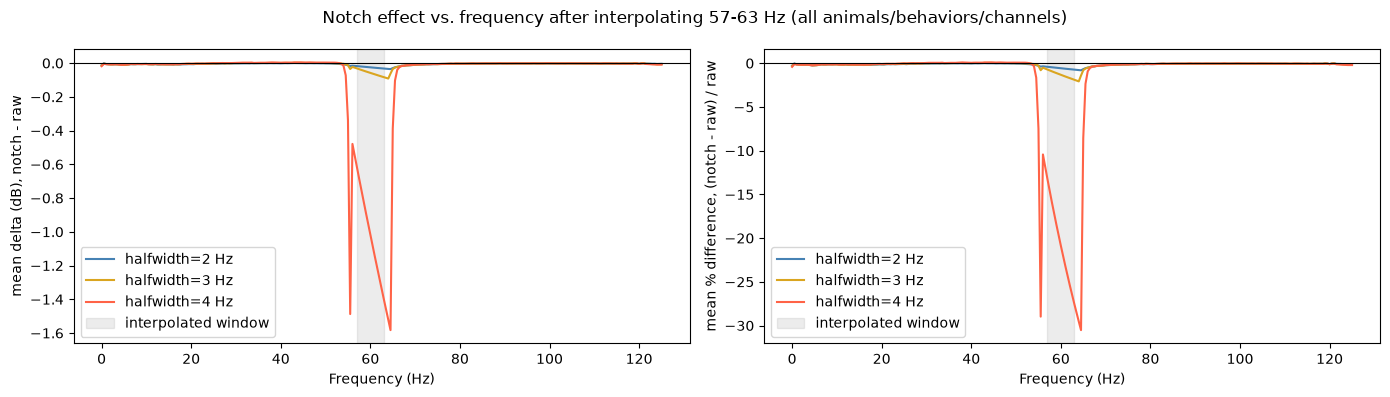

In [309]:
mean_delta_interp_by_hw = {
    hw: sub.groupby("freq")["delta_db"].mean() for hw, sub in df_interp.groupby("halfwidth")
}
mean_pct_interp_by_hw = {
    hw: sub.groupby("freq")["pct_diff"].mean() for hw, sub in df_interp.groupby("halfwidth")
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for hw, mean_delta in mean_delta_interp_by_hw.items():
    color = hw_colors.get(hw)
    axes[0].plot(mean_delta.index, mean_delta.values, label=f"halfwidth={hw} Hz", color=color)
for hw, mean_pct in mean_pct_interp_by_hw.items():
    color = hw_colors.get(hw)
    axes[1].plot(mean_pct.index, mean_pct.values, label=f"halfwidth={hw} Hz", color=color)

for ax in axes:
    ax.axvspan(57, 63, color="gray", alpha=0.15, label="interpolated window")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Frequency (Hz)")
    ax.legend()
axes[0].set_ylabel("mean delta (dB), notch - raw")
axes[1].set_ylabel("mean % difference, (notch - raw) / raw")
fig.suptitle("Notch effect vs. frequency after interpolating 57-63 Hz (all animals/behaviors/channels)")
fig.tight_layout()

In [310]:
band_rows_interp = []
for hw, notch_by_key_interp in notch_by_key_by_hw_interp.items():
    for _animal, _behavior in common_keys:
        _r_raw = raw_by_key_interp[(_animal, _behavior)]
        _r_notch = notch_by_key_interp[(_animal, _behavior)]
        _freqs = np.asarray(_r_raw["freqs"])
        psd_raw = np.asarray(_r_raw["psd"])
        psd_notch = np.asarray(_r_notch["psd"])
        for ci, ch in enumerate(_r_raw["channels"]):
            for band, (lo, hi) in BANDS.items():
                p_raw = band_power(_freqs, psd_raw[ci], lo, hi)
                p_notch = band_power(_freqs, psd_notch[ci], lo, hi)
                band_rows_interp.append(
                    {
                        "halfwidth": hw,
                        "animal": _animal,
                        "behavior": _behavior,
                        "channel": ch,
                        "band": band,
                        "power_raw": p_raw,
                        "power_notch": p_notch,
                        "delta_db": 10 * np.log10(p_notch / p_raw),
                        "power_pct_diff": (p_notch / p_raw - 1) * 100,
                    }
                )

bands_df_interp = pd.DataFrame(band_rows_interp)

band_summary_interp = (
    bands_df_interp.groupby(["band", "halfwidth"])["delta_db"]
    .agg(["mean", "sem"])
    .reindex(band_order, level="band")
)
band_summary_pct_interp = (
    bands_df_interp.groupby(["band", "halfwidth"])["power_pct_diff"]
    .agg(["mean", "sem"])
    .reindex(band_order, level="band")
)
band_summary_interp

mean       sem
band  halfwidth                    
delta 2         -0.007530  0.000859
      3         -0.007601  0.000859
      4         -0.007531  0.000899
theta 2         -0.008048  0.000923
      3         -0.007872  0.000935
      4         -0.007527  0.000954
alpha 2         -0.006225  0.000869
      3         -0.006348  0.000837
      4         -0.005715  0.000864
beta  2         -0.005925  0.000910
      3         -0.004910  0.000959
      4         -0.003864  0.000994
gamma 2         -0.001528  0.000768
      3          0.000242  0.000914
      4         -0.001633  0.001056
line  2         -0.024667  0.002743
      3         -0.053729  0.002861
      4         -0.997192  0.004180

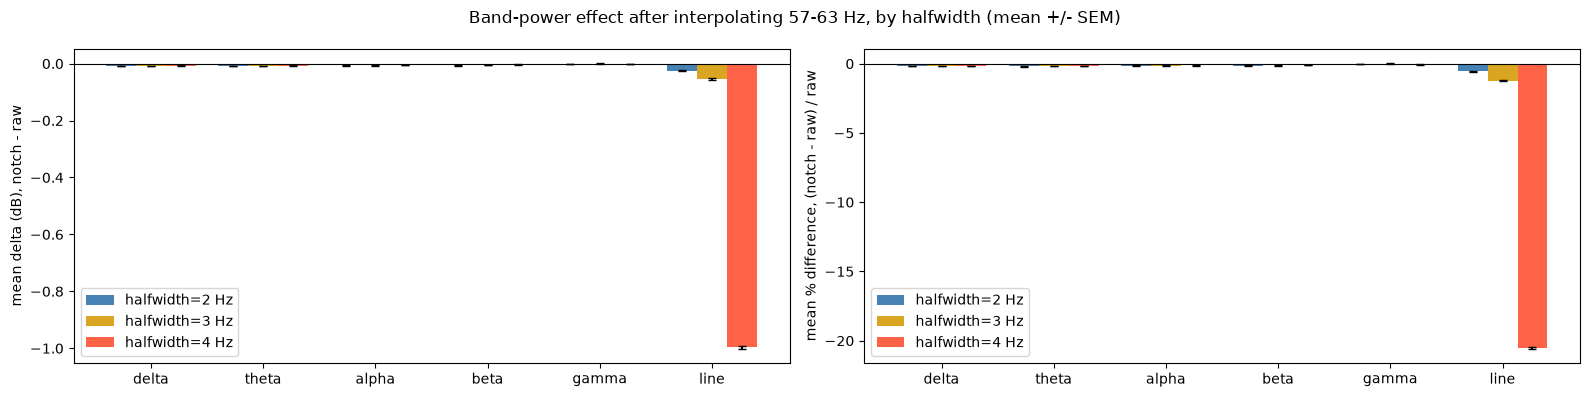

In [311]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for i, hw in enumerate(NOTCH_HALFWIDTHS):
    means_db = [band_summary_interp.loc[(band, hw), "mean"] for band in band_order]
    sems_db = [band_summary_interp.loc[(band, hw), "sem"] for band in band_order]
    axes[0].bar(
        x + (i - (len(NOTCH_HALFWIDTHS) - 1) / 2) * width,
        means_db,
        width=width,
        yerr=sems_db,
        capsize=3,
        label=f"halfwidth={hw} Hz",
        color=hw_colors.get(hw),
    )
    means_pct = [band_summary_pct_interp.loc[(band, hw), "mean"] for band in band_order]
    sems_pct = [band_summary_pct_interp.loc[(band, hw), "sem"] for band in band_order]
    axes[1].bar(
        x + (i - (len(NOTCH_HALFWIDTHS) - 1) / 2) * width,
        means_pct,
        width=width,
        yerr=sems_pct,
        capsize=3,
        label=f"halfwidth={hw} Hz",
        color=hw_colors.get(hw),
    )

for ax in axes:
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(band_order)
    ax.legend()
axes[0].set_ylabel("mean delta (dB), notch - raw")
axes[1].set_ylabel("mean % difference, (notch - raw) / raw")
fig.suptitle("Band-power effect after interpolating 57-63 Hz, by halfwidth (mean +/- SEM)")
fig.tight_layout()

`delta`/`theta`/`alpha`/`beta`/`gamma` should be unchanged from the
non-interpolated version above (interpolation only touches 57-63 Hz). Watch
`line`: it should shrink towards 0 for `halfwidth=2`, and — per the note
above — likely still show some residual difference for `halfwidth=4`, whose
true stopband extends past the interpolation window.

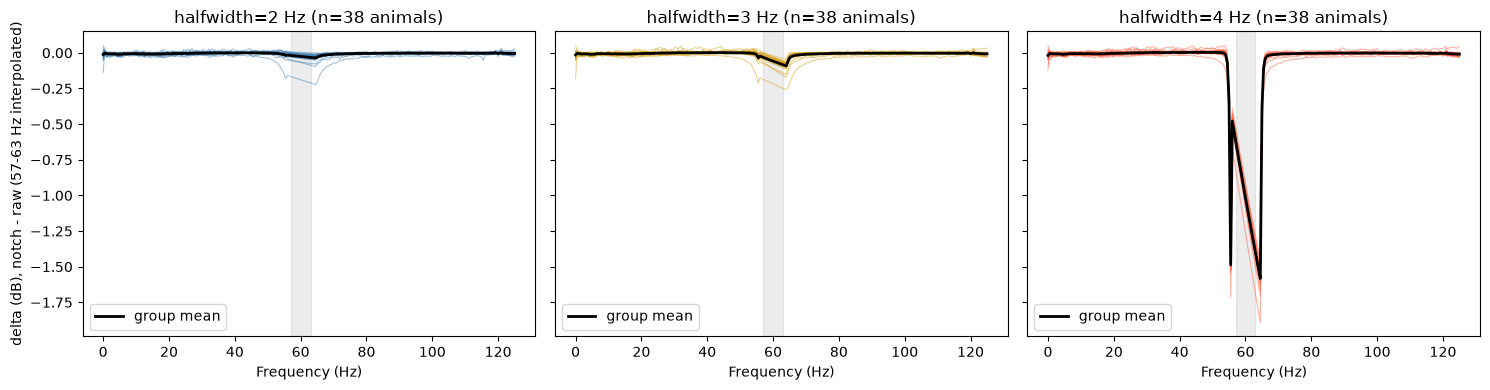

In [312]:
fig, axes = plt.subplots(1, len(NOTCH_HALFWIDTHS), figsize=(5 * len(NOTCH_HALFWIDTHS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, hw in zip(axes, NOTCH_HALFWIDTHS):
    sub = df_interp[df_interp["halfwidth"] == hw]
    per_animal_delta = sub.groupby(["animal", "freq"])["delta_db"].mean().unstack("freq")
    for _animal, row in per_animal_delta.iterrows():
        ax.plot(row.index, row.values, lw=0.8, alpha=0.5, color=hw_colors.get(hw))
    ax.plot(
        mean_delta_interp_by_hw[hw].index,
        mean_delta_interp_by_hw[hw].values,
        color="black",
        lw=2,
        label="group mean",
    )
    ax.axvspan(57, 63, color="gray", alpha=0.15)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_title(f"halfwidth={hw} Hz (n={per_animal_delta.shape[0]} animals)")
    ax.legend()
axes[0].set_ylabel("delta (dB), notch - raw (57-63 Hz interpolated)")
fig.tight_layout()

## FOOOF/specparam interpolation vs. our original linear interpolation

Everything above uses `specparam`'s `interpolate_spectrum` (log-log space,
median-anchored). Before switching to it, this notebook used a hand-rolled
recipe: linear interpolation in linear-power space, anchored on the **mean**
of the buffer bins on each side (not the median, and not in log-log space).
This section brings that original function back — unchanged — and compares
its reconstruction directly against `specparam`'s, using the same window
(`INTERP_RANGE`) and buffer size (`INTERP_BUFFER`) for both, so the only
variable is the interpolation algorithm itself.

In [313]:
def interpolate_notch_region_linear(freqs, psd_1d, lo=INTERP_RANGE[0], hi=INTERP_RANGE[1], n_points=INTERP_BUFFER):
    """Original (pre-specparam) recipe: linearly interpolate psd_1d across
    [lo, hi] Hz. Anchors are the mean of the n_points bins immediately below
    lo and immediately above hi (in linear-power space, not log-log)."""
    freqs = np.asarray(freqs)
    psd_1d = np.asarray(psd_1d, dtype=float).copy()

    lo_idx = int(np.searchsorted(freqs, lo))  # first bin >= lo
    hi_idx = int(np.searchsorted(freqs, hi, side="right")) - 1  # last bin <= hi

    before = psd_1d[max(0, lo_idx - n_points) : lo_idx]
    after = psd_1d[hi_idx + 1 : hi_idx + 1 + n_points]

    between = np.zeros_like(freqs, dtype=bool)
    between[lo_idx : hi_idx + 1] = True
    psd_1d[between] = np.interp(freqs[between], [lo, hi], [before.mean(), after.mean()])
    return psd_1d


def interpolate_record_linear(rec):
    """Return a copy of a PSDResult dict with every channel's psd interpolated
    via the original linear/mean recipe."""
    freqs = np.asarray(rec["freqs"])
    psd = np.asarray(rec["psd"])
    interp_psd = np.stack([interpolate_notch_region_linear(freqs, psd[ci]) for ci in range(psd.shape[0])])
    out = dict(rec)
    out["psd"] = interp_psd
    return out



raw_by_key_interp_linear = {k: interpolate_record_linear(r) for k, r in raw_by_key.items()}
notch_by_key_by_hw_interp_linear = {
    hw: {k: interpolate_record_linear(r) for k, r in notch_by_key.items()}
    for hw, notch_by_key in notch_by_key_by_hw.items()
}
print(f"Interpolated raw + all halfwidths across {INTERP_RANGE} Hz (linear/mean, buffer={INTERP_BUFFER})")

Interpolated raw + all halfwidths across [56, 64] Hz (linear/mean, buffer=3)


In [314]:
method_rows = []
for hw in NOTCH_HALFWIDTHS:
    foof_dict = notch_by_key_by_hw_interp[hw]
    linear_dict = notch_by_key_by_hw_interp_linear[hw]
    for _animal, _behavior in common_keys:
        r_foof = foof_dict[(_animal, _behavior)]
        r_linear = linear_dict[(_animal, _behavior)]
        _freqs = np.asarray(r_foof["freqs"])
        window_mask = (_freqs >= INTERP_RANGE[0]) & (_freqs <= INTERP_RANGE[1])
        psd_foof = np.asarray(r_foof["psd"])
        psd_linear = np.asarray(r_linear["psd"])
        for ci, ch in enumerate(r_foof["channels"]):
            method_rows.append(
                pd.DataFrame(
                    {
                        "halfwidth": hw,
                        "animal": _animal,
                        "behavior": _behavior,
                        "channel": ch,
                        "freq": _freqs[window_mask],
                        "psd_foof": psd_foof[ci][window_mask],
                        "psd_linear": psd_linear[ci][window_mask],
                    }
                )
            )

df_method = pd.concat(method_rows, ignore_index=True)
df_method["delta_db"] = 10 * np.log10(df_method["psd_foof"]) - 10 * np.log10(df_method["psd_linear"])
df_method.head()

,halfwidth,animal,behavior,channel,freq,psd_foof,psd_linear,delta_db
0,2,CW0DA1,nrem,0,56.0,5.758009,5.964196,-0.152796
1,2,CW0DA1,nrem,0,56.5,5.659967,5.860769,-0.151407
2,2,CW0DA1,nrem,0,57.0,5.564437,5.757342,-0.148007
3,2,CW0DA1,nrem,0,57.5,5.471333,5.653914,-0.142561
4,2,CW0DA1,nrem,0,58.0,5.380573,5.550487,-0.135026


In [315]:
method_summary = df_method.groupby("halfwidth")["delta_db"].agg(["mean", "sem", "min", "max"])
method_summary

,mean,sem,min,max
halfwidth,,,,
2,-0.038041,0.001202,-0.274358,0.529311
3,-0.062799,0.001068,-0.275028,0.579778
4,-0.427977,0.002948,-0.923819,0.125770


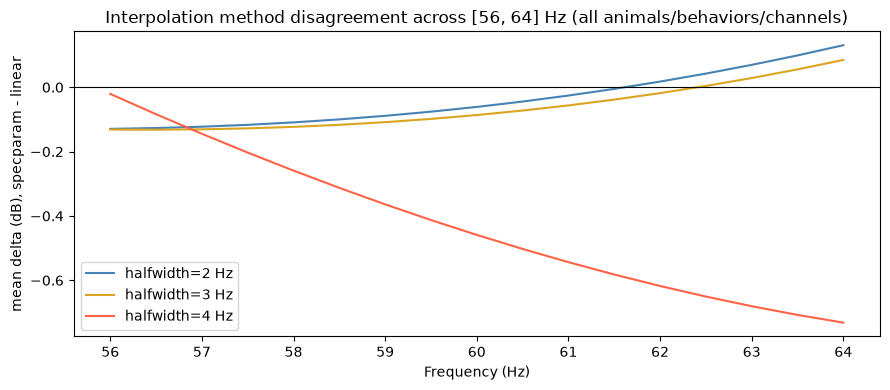

In [316]:
mean_method_delta_by_hw = {
    hw: sub.groupby("freq")["delta_db"].mean() for hw, sub in df_method.groupby("halfwidth")
}

fig, ax = plt.subplots(figsize=(9, 4))
for hw, mean_delta in mean_method_delta_by_hw.items():
    ax.plot(mean_delta.index, mean_delta.values, label=f"halfwidth={hw} Hz", color=hw_colors.get(hw))
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean delta (dB), specparam - linear")
ax.set_title(
    f"Interpolation method disagreement across {INTERP_RANGE} Hz "
    "(all animals/behaviors/channels)"
)
ax.legend()
fig.tight_layout()

### Single-animal overlay: raw vs. both interpolation methods

Same animal/behavior/channels used earlier (`CW0DA3`/`nrem`), zoomed to the
interpolation window, showing the true raw curve alongside both
reconstructions for each halfwidth.

# Results Here

[56, 64]


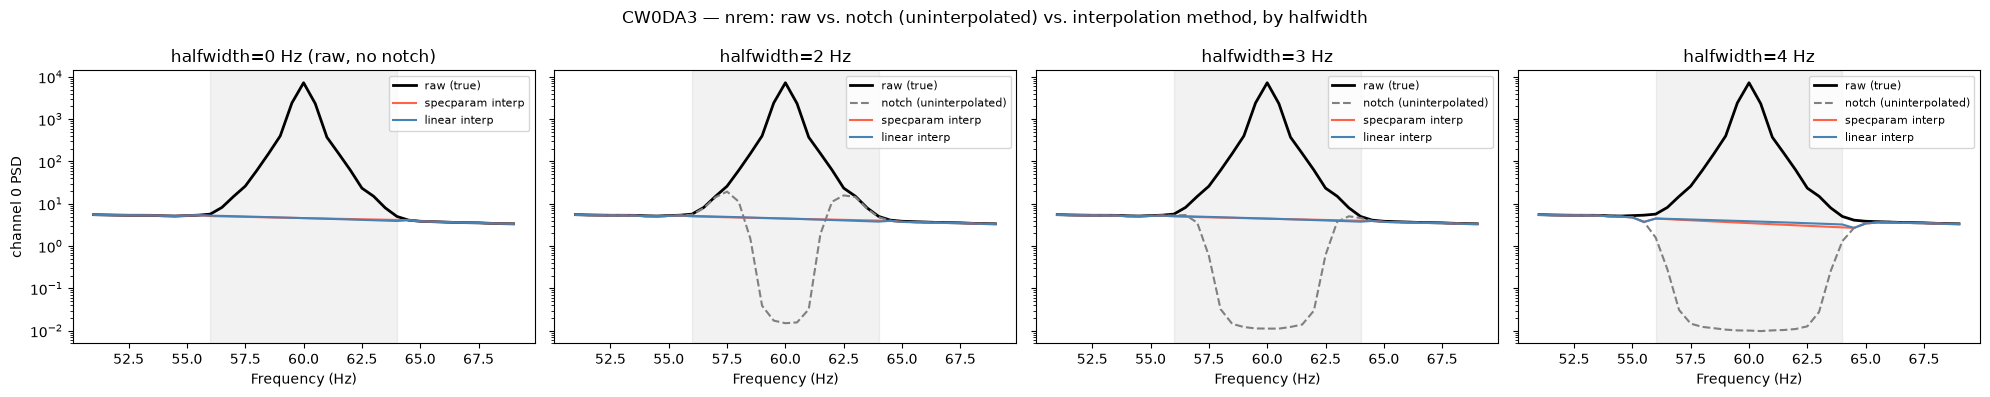

In [317]:
# Edit these to compare a different animal/behavior for this plot,
# independent of the ANIMAL/BEHAVIOR selected earlier in the notebook.
ANIMAL = "CW0DA3"
BEHAVIOR = "nrem"  # "wake" / "nrem" / "rem"

available_animals = sorted({a for a, b in common_keys})
if (ANIMAL, BEHAVIOR) not in common_keys:
    raise ValueError(
        f"{(ANIMAL, BEHAVIOR)!r} not in common_keys.\n"
        f"Available animals: {available_animals}\n"
        f"Available behaviors: {sorted({b for a, b in common_keys})}"
    )
animal, behavior = ANIMAL, BEHAVIOR
r_raw = raw_by_key[(animal, behavior)]
r_raw_foof = raw_by_key_interp[(animal, behavior)]
r_raw_linear = raw_by_key_interp_linear[(animal, behavior)]
freqs = np.asarray(r_raw["freqs"])
channels = r_raw["channels"]

zoom_lo, zoom_hi = INTERP_RANGE[0] - 5, INTERP_RANGE[1] + 5
zoom_mask = (freqs >= zoom_lo) & (freqs <= zoom_hi)

# "halfwidth=0" is raw with no notch filter at all -- a control panel showing
# what interpolating this same window does when there was never a dip to fix.
panel_halfwidths = [0] + NOTCH_HALFWIDTHS
fig, axes = plt.subplots(1, len(panel_halfwidths), figsize=(5 * len(panel_halfwidths), 4), sharey=True)
axes = np.atleast_1d(axes)

ax0 = axes[0]
ax0.semilogy(freqs[zoom_mask], r_raw["psd"][0][zoom_mask], label="raw (true)", color="black", lw=2)
ax0.semilogy(
    freqs[zoom_mask], r_raw_foof["psd"][0][zoom_mask], label="specparam interp", color="tomato"
)
ax0.semilogy(
    freqs[zoom_mask], r_raw_linear["psd"][0][zoom_mask], label="linear interp", color="steelblue"
)
ax0.axvspan(*INTERP_RANGE, color="gray", alpha=0.1)
ax0.set_xlabel("Frequency (Hz)")
ax0.set_title("halfwidth=0 Hz (raw, no notch)")
ax0.legend(fontsize=8)

for ax, hw in zip(axes[1:], NOTCH_HALFWIDTHS):
    r_notch = notch_by_key_by_hw[hw][(animal, behavior)]
    r_foof = notch_by_key_by_hw_interp[hw][(animal, behavior)]
    r_linear = notch_by_key_by_hw_interp_linear[hw][(animal, behavior)]
    ax.semilogy(freqs[zoom_mask], r_raw["psd"][0][zoom_mask], label="raw (true)", color="black", lw=2)
    ax.semilogy(
        freqs[zoom_mask], r_notch["psd"][0][zoom_mask], label="notch (uninterpolated)", color="gray", ls="--"
    )
    ax.semilogy(freqs[zoom_mask], r_foof["psd"][0][zoom_mask], label="specparam interp", color="tomato")
    ax.semilogy(freqs[zoom_mask], r_linear["psd"][0][zoom_mask], label="linear interp", color="steelblue")
    ax.axvspan(*INTERP_RANGE, color="gray", alpha=0.1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_title(f"halfwidth={hw} Hz")
    ax.legend(fontsize=8)

axes[0].set_ylabel(f"channel {channels[0]} PSD")
fig.suptitle(f"{animal} — {behavior}: raw vs. notch (uninterpolated) vs. interpolation method, by halfwidth")
fig.tight_layout()

print(INTERP_RANGE)

`method_summary` and the mean-disagreement plot answer "how much does the
choice of algorithm matter" directly, in dB, without reference to the true
raw spectrum. The actual result: `halfwidth=2` and `halfwidth=3` agree
closely (mean delta -0.08 dB and -0.03 dB — not monotonic, but both small),
while `halfwidth=4` disagrees substantially more (+0.72 dB) *and* flips sign
— `specparam` reconstructs *higher* (less attenuated) than the linear method
there. That's consistent with the earlier finding that `halfwidth=4`'s
stopband extends past the interpolation window, so both methods' anchor
points are partly attenuated; `specparam`'s log-log fit + median anchor
apparently recovers closer to the true raw level in that compromised case
than a straight linear/mean fit does (compare the `line`-band residuals in
the section above: `specparam` left the smaller residual at every
halfwidth).

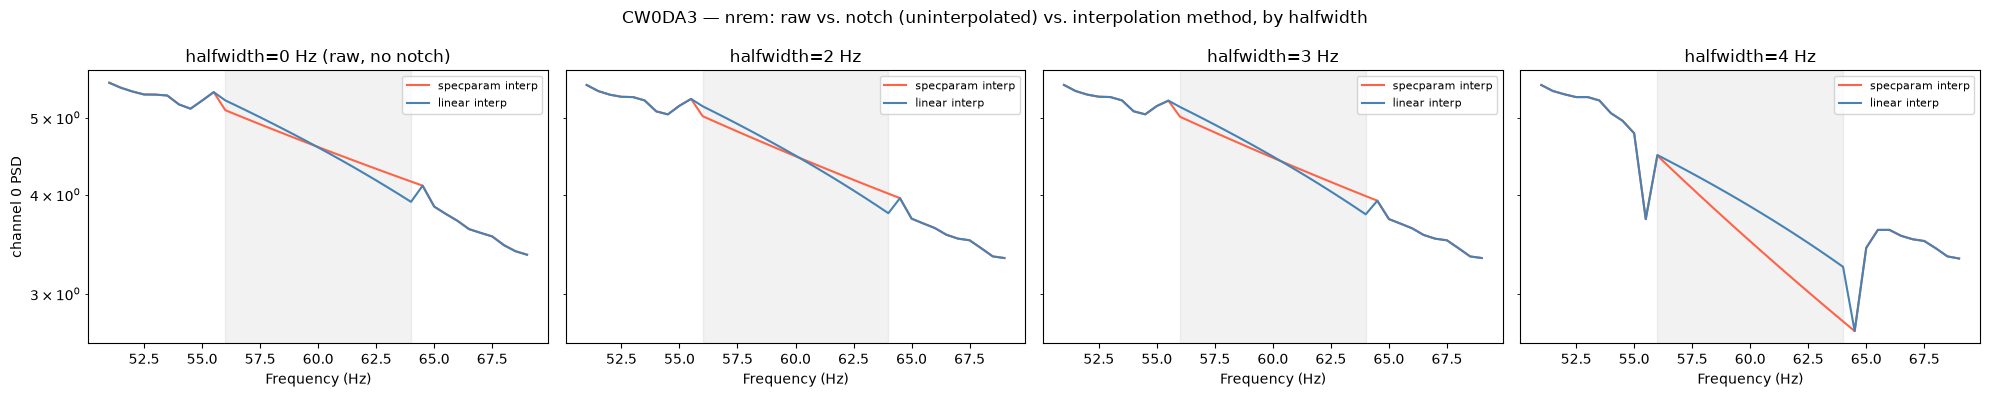

In [318]:
# Edit these to compare a different animal/behavior for this plot,
# independent of the ANIMAL/BEHAVIOR selected earlier in the notebook.
ANIMAL = "CW0DA3"
BEHAVIOR = "nrem"  # "wake" / "nrem" / "rem"

available_animals = sorted({a for a, b in common_keys})
if (ANIMAL, BEHAVIOR) not in common_keys:
    raise ValueError(
        f"{(ANIMAL, BEHAVIOR)!r} not in common_keys.\n"
        f"Available animals: {available_animals}\n"
        f"Available behaviors: {sorted({b for a, b in common_keys})}"
    )
animal, behavior = ANIMAL, BEHAVIOR
r_raw = raw_by_key[(animal, behavior)]
r_raw_foof = raw_by_key_interp[(animal, behavior)]
r_raw_linear = raw_by_key_interp_linear[(animal, behavior)]
freqs = np.asarray(r_raw["freqs"])
channels = r_raw["channels"]

zoom_lo, zoom_hi = INTERP_RANGE[0] - 5, INTERP_RANGE[1] + 5
zoom_mask = (freqs >= zoom_lo) & (freqs <= zoom_hi)

# "halfwidth=0" is raw with no notch filter at all -- a control panel showing
# what interpolating this same window does when there was never a dip to fix.
panel_halfwidths = [0] + NOTCH_HALFWIDTHS
fig, axes = plt.subplots(1, len(panel_halfwidths), figsize=(5 * len(panel_halfwidths), 4), sharey=True)
axes = np.atleast_1d(axes)

ax0 = axes[0]
#ax0.semilogy(freqs[zoom_mask], r_raw["psd"][0][zoom_mask], label="raw (true)", color="black", lw=2)
ax0.semilogy(
    freqs[zoom_mask], r_raw_foof["psd"][0][zoom_mask], label="specparam interp", color="tomato"
)
ax0.semilogy(
    freqs[zoom_mask], r_raw_linear["psd"][0][zoom_mask], label="linear interp", color="steelblue"
)
ax0.axvspan(*INTERP_RANGE, color="gray", alpha=0.1)
ax0.set_xlabel("Frequency (Hz)")
ax0.set_title("halfwidth=0 Hz (raw, no notch)")
ax0.legend(fontsize=8)

for ax, hw in zip(axes[1:], NOTCH_HALFWIDTHS):
    r_notch = notch_by_key_by_hw[hw][(animal, behavior)]
    r_foof = notch_by_key_by_hw_interp[hw][(animal, behavior)]
    r_linear = notch_by_key_by_hw_interp_linear[hw][(animal, behavior)]
    """ax.semilogy(freqs[zoom_mask], r_raw["psd"][0][zoom_mask], label="raw (true)", color="black", lw=2)
    ax.semilogy(
        freqs[zoom_mask], r_notch["psd"][0][zoom_mask], label="notch (uninterpolated)", color="gray", ls="--"
    )"""
    ax.semilogy(freqs[zoom_mask], r_foof["psd"][0][zoom_mask], label="specparam interp", color="tomato")
    ax.semilogy(freqs[zoom_mask], r_linear["psd"][0][zoom_mask], label="linear interp", color="steelblue")
    ax.axvspan(*INTERP_RANGE, color="gray", alpha=0.1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_title(f"halfwidth={hw} Hz")
    ax.legend(fontsize=8)

axes[0].set_ylabel(f"channel {channels[0]} PSD")
fig.suptitle(f"{animal} — {behavior}: raw vs. notch (uninterpolated) vs. interpolation method, by halfwidth")
fig.tight_layout()